# Практична робота 3
## Перша модель і базове оцінювання якості
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студентка:** Софія Фесенко  
**Група:** ІН-32  
**Дата виконання:** 10/11/2026  

### Мета роботи
Побудувати першу завершену модель машинного навчання, отримати прогнози та навчитися оцінювати їхню якість за допомогою основних метрик класифікації.

In [ ]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

# Налаштування шляхів
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "iris_cleaned.csv"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODEL_PATH = MODELS_DIR / "iris_decision_tree.joblib"
METRICS_PATH = REPORTS_DIR / "model_metrics.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH)
print("Файл моделі:", MODEL_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Файл даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Файл моделі: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


## 2. Завантаження підготовленого набору даних
Завантаження очищеної таблиці з результатами попередньої практичної роботи для побудови моделей класифікації.

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл iris_cleaned.csv не знайдено. Перевірте виконання практичної роботи 2."
    )

data = pd.read_csv(DATA_PATH)
display(data.head())

print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)
print("\nКількість пропусків:", data.isna().sum().sum())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (148, 6)

Типи даних:
sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                object
measurement_device     object
dtype: object

Кількість пропусків: 0


### Відповіді на запитання щодо даних:
1. Скільки об'єктів містить очищений набір? - 148 об'єктів.
2. Скільки ознак доступно? - 4 числові та категоріальна ознака пристрою.
3. Чи залишилися пропущені значення? - Ні, пропуски відсутні (0).
4. Який стовпець є цільовою змінною? - `species` (вид ірису).

In [ ]:
X = data.drop(columns=["species"])
y = data["species"]

categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Категоріальні ознаки:", categorical_columns)

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

display(X.head())
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Категоріальні ознаки: ['measurement_device']


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


Розмір X: (148, 7)
Розмір y: (148,)


### Пояснення щодо формування вибірок:
- Тестова вибірка виділяється для незалежного оцінювання узагальнювальної здатності моделі й не використовується для навчання.
- `random_state=42` забезпечує відтворюваність та ідентичність розбиття.
- `stratify=y` гарантує збереження рівномірного співвідношення класів у train і test.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

split_distribution = pd.DataFrame(
    {
        "train_percent": (
            y_train
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
display(split_distribution)

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


,train_percent,test_percent
species,,
setosa,33.90,33.33
versicolor,33.05,33.33
virginica,33.05,33.33


## 3. Базова модель DummyClassifier
DummyClassifier використовується як найпростіший орієнтир (бенчмарк).

In [ ]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_train_predictions = dummy_model.predict(X_train)
dummy_test_predictions = dummy_model.predict(X_test)

dummy_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:10].values,
        "predicted": dummy_test_predictions[:10]
    }
)
display(dummy_preview)

,actual,predicted
0,versicolor,setosa
1,versicolor,setosa
2,virginica,setosa
3,setosa,setosa
4,virginica,setosa
5,versicolor,setosa
6,versicolor,setosa
7,setosa,setosa
8,virginica,setosa
9,virginica,setosa


## 4. Дерево рішень
Будується перша  модель - дерево рішень з обмеженою глибиною (`max_depth=3`).

In [ ]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
tree_model.fit(X_train, y_train)

tree_train_predictions = tree_model.predict(X_train)
tree_test_predictions = tree_model.predict(X_test)

prediction_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:15].values,
        "predicted": tree_test_predictions[:15]
    }
)
prediction_preview["correct"] = (
    prediction_preview["actual"] == prediction_preview["predicted"]
)
display(prediction_preview)

,actual,predicted,correct
0,versicolor,versicolor,True
1,versicolor,versicolor,True
2,virginica,virginica,True
3,setosa,setosa,True
4,virginica,virginica,True
5,versicolor,versicolor,True
6,versicolor,versicolor,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,virginica,True


,model,dataset,accuracy,precision_macro,recall_macro,f1_macro
0,DummyClassifier,train,0.339,0.113,0.333,0.169
1,DummyClassifier,test,0.333,0.111,0.333,0.167
2,DecisionTree,train,0.975,0.975,0.975,0.974
3,DecisionTree,test,0.967,0.970,0.967,0.967


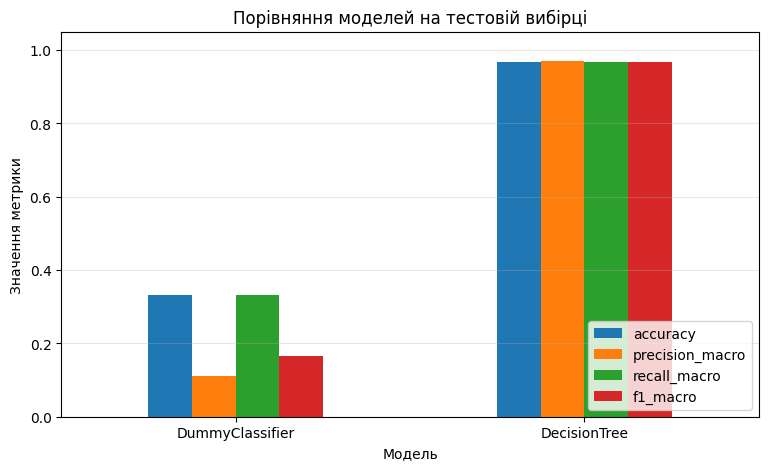

In [ ]:
def calculate_metrics(model_name, dataset_name, y_true, y_pred):
    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

metrics_rows = [
    calculate_metrics("DummyClassifier", "train", y_train, dummy_train_predictions),
    calculate_metrics("DummyClassifier", "test", y_test, dummy_test_predictions),
    calculate_metrics("DecisionTree", "train", y_train, tree_train_predictions),
    calculate_metrics("DecisionTree", "test", y_test, tree_test_predictions)
]

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df.round(3))

# Візуальне порівняння на тестовій вибірці
test_metrics = (
    metrics_df[metrics_df["dataset"] == "test"]
    .set_index("model")
)
test_metrics[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Порівняння моделей на тестовій вибірці")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.show()

In [ ]:
train_test_comparison = metrics_df.pivot(
    index="model",
    columns="dataset",
    values=["accuracy", "f1_macro"]
)
display(train_test_comparison.round(3))

tree_train_accuracy = accuracy_score(y_train, tree_train_predictions)
tree_test_accuracy = accuracy_score(y_test, tree_test_predictions)
accuracy_gap = tree_train_accuracy - tree_test_accuracy

print("Accuracy на train:", round(tree_train_accuracy, 3))
print("Accuracy на test:", round(tree_test_accuracy, 3))
print("Різниця:", round(accuracy_gap, 3))

accuracy        f1_macro       
dataset             test  train     test  train
model                                          
DecisionTree       0.967  0.975    0.967  0.974
DummyClassifier    0.333  0.339    0.167  0.169

Accuracy на train: 0.975
Accuracy на test: 0.967
Різниця: 0.008


## 5. Матриця помилок
Матриця помилок дозволяє побачити, які класи модель визначає правильно, а які плутає між собою.

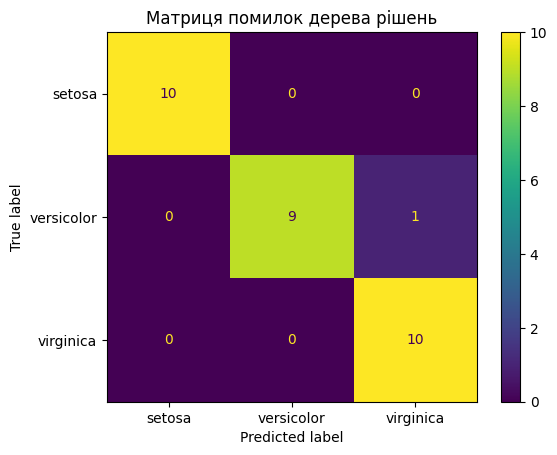

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,actual,predicted,correct
77,6.7,3.0,5.0,1.7,0,1,0,versicolor,virginica,False


Кількість помилкових прогнозів: 1


In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_test_predictions
)
plt.title("Матриця помилок дерева рішень")
plt.show()

test_results = X_test.copy()
test_results["actual"] = y_test.values
test_results["predicted"] = tree_test_predictions
test_results["correct"] = (
    test_results["actual"] == test_results["predicted"]
)

mistakes = test_results[~test_results["correct"]]
display(mistakes)
print("Кількість помилкових прогнозів:", len(mistakes))

## 6. Збереження навченої моделі
Збереження моделі разом із назвами ознак та класами у форматі `.joblib`.

In [ ]:
model_bundle = {
    "model": tree_model,
    "feature_columns": X.columns.tolist(),
    "target_classes": sorted(y.unique().tolist())
}

joblib.dump(model_bundle, MODEL_PATH)
print("Модель збережено:", MODEL_PATH)

loaded_bundle = joblib.load(MODEL_PATH)
loaded_model = loaded_bundle["model"]
print("Ознаки моделі:", loaded_bundle["feature_columns"])
print("Класи:", loaded_bundle["target_classes"])

metrics_df.to_csv(METRICS_PATH, index=False)
print("Таблицю метрик збережено:", METRICS_PATH)

Модель збережено: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib
Ознаки моделі: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'measurement_device_device_a', 'measurement_device_device_b', 'measurement_device_device_c']
Класи: ['setosa', 'versicolor', 'virginica']
Таблицю метрик збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/model_metrics.csv


In [ ]:
assert X_train.isna().sum().sum() == 0, "У X_train залишилися пропуски."
assert X_test.isna().sum().sum() == 0, "У X_test залишилися пропуски."
assert len(tree_test_predictions) == len(y_test), "Кількість прогнозів не відповідає кількості тестових об'єктів."
assert set(tree_test_predictions).issubset(set(y_train.unique())), "Модель прогнозує невідомий клас."
assert MODEL_PATH.exists(), "Файл моделі не збережено."
assert tree_test_accuracy > accuracy_score(y_test, dummy_test_predictions), "Дерево не перевищує базову модель."
print("Усі основні перевірки виконано успішно.")

Усі основні перевірки виконано успішно.
